In [1]:
# =============================================================================
# RICE LEAF DISEASE CLASSIFICATION - CLASSICAL MACHINE LEARNING PIPELINE
# Chạy trực tiếp trên Kaggle Notebook (copy từng "# %%" thành 1 cell riêng,
# hoặc import file này như notebook bằng Jupytext)
# =============================================================================

# PHẦN 1: Cấu trúc project, import, cấu hình, preprocessing
#
## Cấu trúc thư mục dataset (trên Kaggle):
```
/kaggle/input/<ten-dataset>/
  ├── train/
  │   ├── Bacterial Leaf Blight/
  │   ├── Brown Spot/
  │   ├── Healthy Rice Leaf/
  │   ├── Leaf Blast/
  │   ├── Leaf scald/
  │   ├── Narrow Brown Leaf Spot/
  │   ├── Rice Hispa/
  │   └── Sheath Blight/
  ├── test_images/
  ├── sample_submission.csv
  └── label_mapping.json
```

In [2]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

from skimage.feature import hog, local_binary_pattern
from skimage import color

from sklearn.model_selection import (
    train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold
)
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score, f1_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_style("whitegrid")


# ---------------------------------------------------------------------------
# CẤU HÌNH TOÀN CỤC (CONFIG)
# ---------------------------------------------------------------------------
class CFG:
    # ⚠️ SỬA LẠI đường dẫn dataset đúng theo tên hiển thị trong "Data Explorer"
    DATA_DIR = "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup"
    TRAIN_DIR = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/train")
    TEST_DIR = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/test_warmup")
    LABEL_MAP_PATH = os.path.join(DATA_DIR, "/kaggle/input/competitions/fptu-can-tho-olympic-ai-2026-vong-lo-i-warmup/label_mapping.json")
    SAMPLE_SUB_PATH = os.path.join(DATA_DIR, "sample_submission.csv")

    IMG_SIZE = (128, 128)      # resize ảnh về cùng kích thước
    RANDOM_STATE = 42
    TEST_SIZE = 0.2            # tỉ lệ tách validation từ train

    # Tham số HOG (Histogram of Oriented Gradients)
    HOG_ORIENTATIONS = 9
    HOG_PIXELS_PER_CELL = (8, 8)
    HOG_CELLS_PER_BLOCK = (2, 2)

    # Tham số LBP (Local Binary Pattern)
    LBP_RADIUS = 3
    LBP_N_POINTS = 8 * LBP_RADIUS
    LBP_METHOD = "uniform"

    # Tham số Color Histogram
    COLOR_BINS = 32


np.random.seed(CFG.RANDOM_STATE)

# Đọc file ánh xạ nhãn
with open(CFG.LABEL_MAP_PATH, "r", encoding="utf-8") as f:
    label_mapping = json.load(f)
print("Label mapping:", label_mapping)

idx_to_class = {v: k for k, v in label_mapping.items()}


def load_and_preprocess_image(path, size=CFG.IMG_SIZE):
    """
    Đọc ảnh từ đường dẫn, chuyển BGR->RGB, resize về kích thước cố định.
    Trả về ảnh dạng numpy array (H, W, 3), giá trị 0-255.
    """
    img = cv2.imread(path)
    if img is None:
        raise FileNotFoundError(f"Không đọc được ảnh: {path}")
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    return img

Label mapping: {'Bacterial Leaf Blight': 0, 'Brown Spot': 1, 'Healthy Rice Leaf': 2, 'Leaf Blast': 3, 'Leaf scald': 4, 'Narrow Brown Leaf Spot': 5, 'Rice Hispa': 6, 'Sheath Blight': 7}


# PHẦN 2: Feature Extraction (HOG, LBP, Color Histogram)

In [3]:
def extract_hog_features(img):
    """
    Trích xuất đặc trưng hình dạng/cạnh (shape/edge) bằng HOG.
    HOG mô tả hướng và cường độ gradient trong từng ô nhỏ (cell) của ảnh,
    rất phù hợp để mô tả hình dạng tổn thương/vết bệnh trên lá.
    """
    gray = color.rgb2gray(img)
    features = hog(
        gray,
        orientations=CFG.HOG_ORIENTATIONS,
        pixels_per_cell=CFG.HOG_PIXELS_PER_CELL,
        cells_per_block=CFG.HOG_CELLS_PER_BLOCK,
        block_norm="L2-Hys",
        feature_vector=True,
    )
    return features


def extract_lbp_features(img):
    """
    Trích xuất đặc trưng kết cấu (texture) bằng Local Binary Pattern.
    LBP mã hóa mối quan hệ độ sáng giữa 1 pixel và các pixel lân cận,
    hữu ích để phân biệt kết cấu bề mặt lá (mượt, sần, có đốm...).
    Trả về histogram (phân bố tần suất) đã chuẩn hóa của các mã LBP.
    """
    gray = color.rgb2gray(img)
    gray_uint8 = (gray * 255).astype(np.uint8)
    lbp = local_binary_pattern(
        gray_uint8, CFG.LBP_N_POINTS, CFG.LBP_RADIUS, method=CFG.LBP_METHOD
    )
    n_bins = int(lbp.max() + 1)
    hist, _ = np.histogram(
        lbp.ravel(), bins=n_bins, range=(0, n_bins), density=True
    )
    return hist


def extract_color_histogram(img, bins=CFG.COLOR_BINS):
    """
    Trích xuất đặc trưng màu sắc bằng histogram trên 3 kênh R, G, B.
    Giúp phân biệt vùng bệnh có màu vàng/nâu/đỏ khác với vùng lá khỏe (xanh).
    """
    hist_features = []
    for i in range(3):  # R, G, B
        hist = cv2.calcHist([img], [i], None, [bins], [0, 256])
        hist = cv2.normalize(hist, hist).flatten()
        hist_features.extend(hist)
    return np.array(hist_features)


def extract_combined_features(img):
    """
    Ghép 3 loại đặc trưng (HOG + LBP + Color Histogram) thành 1 vector duy nhất
    đại diện cho ảnh, dùng làm input cho các mô hình ML cổ điển.
    """
    hog_feat = extract_hog_features(img)
    lbp_feat = extract_lbp_features(img)
    color_feat = extract_color_histogram(img)
    return np.concatenate([hog_feat, lbp_feat, color_feat])

# PHẦN 3: Đọc dataset, EDA và xây dựng feature matrix

In [4]:
def build_file_list(train_dir, label_mapping):
    """Duyệt qua từng thư mục lớp bệnh, thu thập đường dẫn ảnh + nhãn tương ứng."""
    records = []
    for class_name, class_idx in label_mapping.items():
        class_dir = os.path.join(train_dir, class_name)
        if not os.path.isdir(class_dir):
            print(f"⚠️ Không tìm thấy thư mục: {class_dir}")
            continue
        for fname in os.listdir(class_dir):
            if fname.lower().endswith((".jpg", ".jpeg", ".png")):
                records.append({
                    "filepath": os.path.join(class_dir, fname),
                    "label": class_idx,
                    "class_name": class_name,
                })
    return pd.DataFrame(records)


train_df = build_file_list(CFG.TRAIN_DIR, label_mapping)
print("Tổng số ảnh train:", train_df.shape[0])
train_df.head()

Tổng số ảnh train: 2026


,filepath,label,class_name
0,/kaggle/input/competitions/fptu-can-tho-olympi...,0,Bacterial Leaf Blight
1,/kaggle/input/competitions/fptu-can-tho-olympi...,0,Bacterial Leaf Blight
2,/kaggle/input/competitions/fptu-can-tho-olympi...,0,Bacterial Leaf Blight
3,/kaggle/input/competitions/fptu-can-tho-olympi...,0,Bacterial Leaf Blight
4,/kaggle/input/competitions/fptu-can-tho-olympi...,0,Bacterial Leaf Blight


## EDA - Phân bố lớp

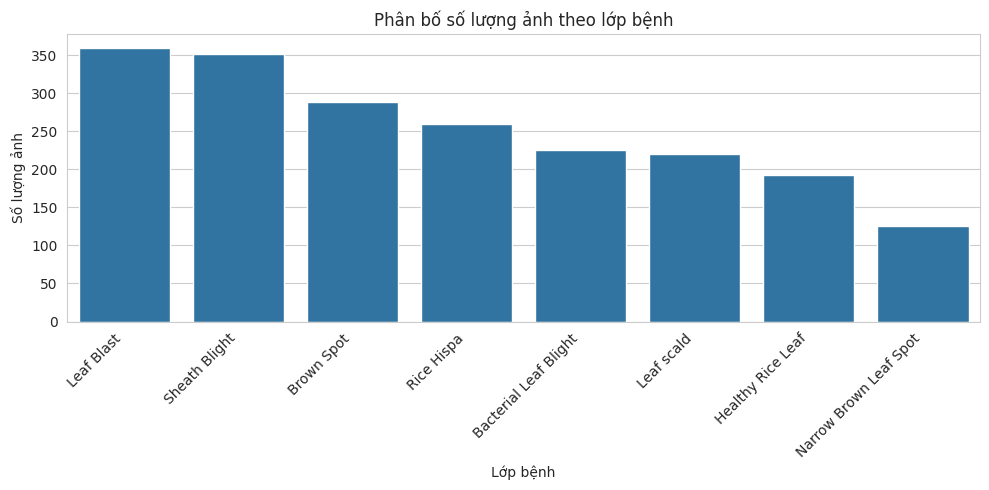

class_name
Leaf Blast                360
Sheath Blight             352
Brown Spot                289
Rice Hispa                260
Bacterial Leaf Blight     226
Leaf scald                220
Healthy Rice Leaf         193
Narrow Brown Leaf Spot    126
Name: count, dtype: int64


In [5]:
plt.figure(figsize=(10, 5))
order = train_df["class_name"].value_counts().index
sns.countplot(data=train_df, x="class_name", order=order)
plt.xticks(rotation=45, ha="right")
plt.title("Phân bố số lượng ảnh theo lớp bệnh")
plt.ylabel("Số lượng ảnh")
plt.xlabel("Lớp bệnh")
plt.tight_layout()
plt.show()

print(train_df["class_name"].value_counts())

## EDA - Xem ảnh mẫu mỗi lớp

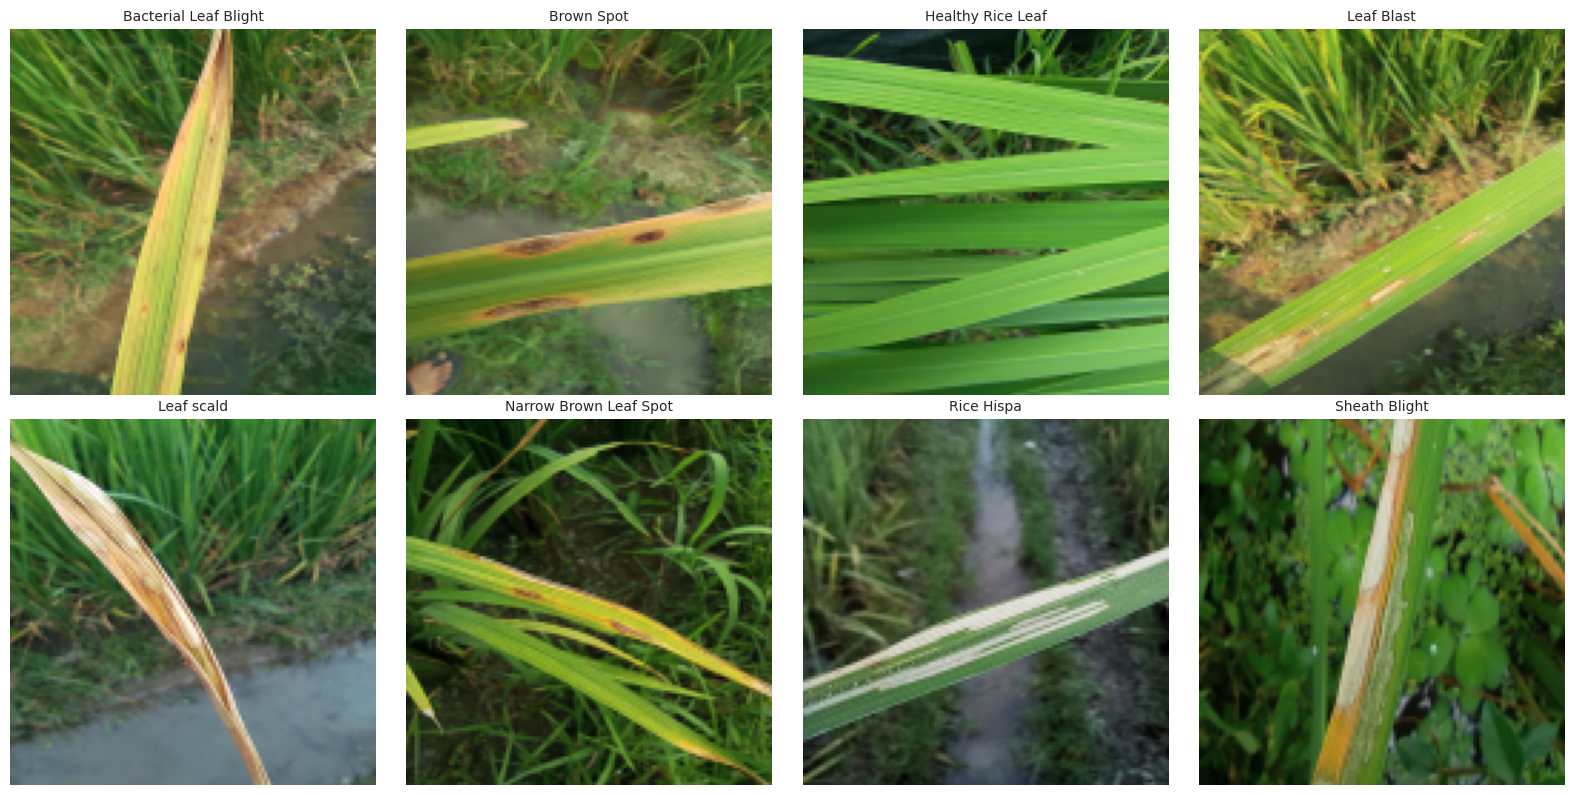

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, (class_name, class_idx) in zip(axes.ravel(), label_mapping.items()):
    sample_path = train_df[train_df["class_name"] == class_name]["filepath"].iloc[0]
    img = load_and_preprocess_image(sample_path)
    ax.imshow(img)
    ax.set_title(class_name, fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Xây dựng feature matrix cho toàn bộ tập train

In [7]:
def build_feature_matrix(df):
    """Đọc từng ảnh, trích xuất đặc trưng, gom thành ma trận X và vector nhãn y."""
    X, y = [], []
    for _, row in tqdm(df.iterrows(), total=len(df)):
        img = load_and_preprocess_image(row["filepath"])
        feat = extract_combined_features(img)
        X.append(feat)
        y.append(row["label"])
    return np.array(X), np.array(y)


X, y = build_feature_matrix(train_df)
print("Kích thước feature matrix:", X.shape)

# Chuẩn hóa đặc trưng (quan trọng với SVM, KNN, Logistic Regression)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_val, y_train, y_val = train_test_split(
    X_scaled, y, test_size=CFG.TEST_SIZE,
    random_state=CFG.RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Validation:", X_val.shape)

100%|██████████| 2026/2026 [01:55<00:00, 17.60it/s]


Kích thước feature matrix: (2026, 8222)
Train: (1620, 8222)  Validation: (406, 8222)


# PHẦN 4: Huấn luyện SVM, KNN, Decision Tree, Logistic Regression

In [8]:
models = {
    "SVM": SVC(kernel="rbf", C=10, gamma="scale",
               probability=True, random_state=CFG.RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "DecisionTree": DecisionTreeClassifier(max_depth=15,
                                            random_state=CFG.RANDOM_STATE),
    "LogisticRegression": LogisticRegression(max_iter=2000,
                                              random_state=CFG.RANDOM_STATE),
}

trained_models = {}
results = {}

for name, model in models.items():
    print(f"\n===== Huấn luyện {name} =====")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    acc = accuracy_score(y_val, y_pred)
    f1 = f1_score(y_val, y_pred, average="macro")
    results[name] = {"accuracy": acc, "f1_macro": f1}
    trained_models[name] = model
    print(f"Accuracy: {acc:.4f} | F1-macro: {f1:.4f}")

results_df = pd.DataFrame(results).T.sort_values("f1_macro", ascending=False)
print("\nBảng so sánh các mô hình:")
print(results_df)


===== Huấn luyện SVM =====
Accuracy: 0.7759 | F1-macro: 0.7569

===== Huấn luyện KNN =====
Accuracy: 0.5517 | F1-macro: 0.5116

===== Huấn luyện DecisionTree =====
Accuracy: 0.5690 | F1-macro: 0.5358

===== Huấn luyện LogisticRegression =====
Accuracy: 0.7463 | F1-macro: 0.7229

Bảng so sánh các mô hình:
                    accuracy  f1_macro
SVM                 0.775862  0.756858
LogisticRegression  0.746305  0.722932
DecisionTree        0.568966  0.535812
KNN                 0.551724  0.511613


# PHẦN 5: Voting Ensemble, đánh giá, confusion matrix

Voting Ensemble - Accuracy: 0.7906 | F1-macro: 0.7709

Classification report (Voting Ensemble):
                        precision    recall  f1-score   support

 Bacterial Leaf Blight       0.72      0.84      0.78        45
            Brown Spot       0.87      0.83      0.85        58
     Healthy Rice Leaf       0.80      0.72      0.76        39
            Leaf Blast       0.85      0.89      0.87        72
            Leaf scald       0.86      0.68      0.76        44
Narrow Brown Leaf Spot       0.70      0.56      0.62        25
            Rice Hispa       0.70      0.75      0.72        52
         Sheath Blight       0.78      0.85      0.81        71

              accuracy                           0.79       406
             macro avg       0.78      0.76      0.77       406
          weighted avg       0.79      0.79      0.79       406



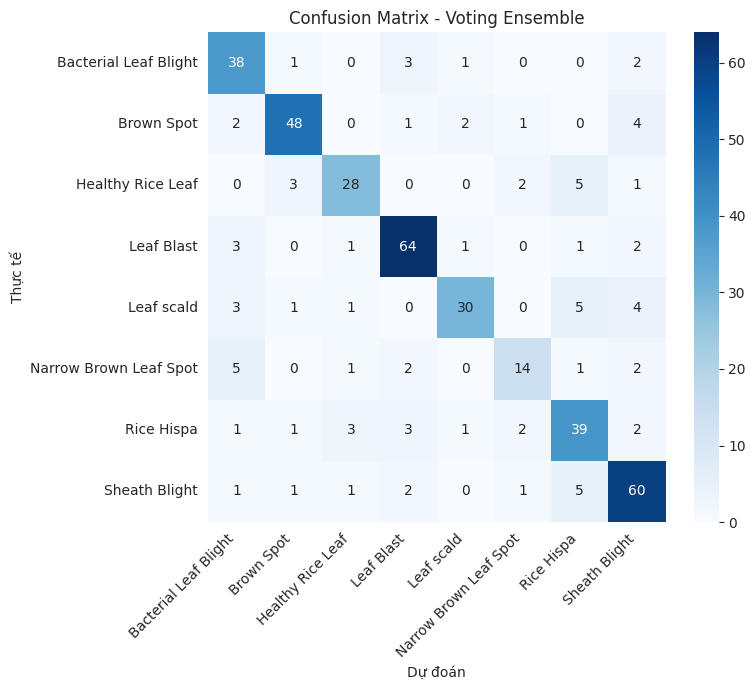

In [9]:
voting_clf = VotingClassifier(
    estimators=[
        ("svm", trained_models["SVM"]),
        ("knn", trained_models["KNN"]),
        ("dt", trained_models["DecisionTree"]),
        ("lr", trained_models["LogisticRegression"]),
    ],
    voting="soft",   # dùng xác suất trung bình thay vì chỉ đếm phiếu bầu
)
voting_clf.fit(X_train, y_train)
y_pred_vote = voting_clf.predict(X_val)

acc_vote = accuracy_score(y_val, y_pred_vote)
f1_vote = f1_score(y_val, y_pred_vote, average="macro")
print(f"Voting Ensemble - Accuracy: {acc_vote:.4f} | F1-macro: {f1_vote:.4f}")

print("\nClassification report (Voting Ensemble):")
print(classification_report(
    y_val, y_pred_vote, target_names=list(label_mapping.keys())
))

# Confusion matrix
cm = confusion_matrix(y_val, y_pred_vote)
plt.figure(figsize=(8, 7))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=list(label_mapping.keys()),
    yticklabels=list(label_mapping.keys()),
)
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.title("Confusion Matrix - Voting Ensemble")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## 5b. Stacking Ensemble
#
Khác với Voting (chỉ lấy trung bình/đa số phiếu), **Stacking** huấn luyện
thêm một mô hình "meta" (ở đây là Logistic Regression) học cách kết hợp
tối ưu đầu ra (xác suất dự đoán) của các mô hình gốc (base learners).
Nhờ có cross-validation nội bộ (`cv=5`) khi tạo dữ liệu cho meta model,
Stacking thường tổng quát hóa tốt hơn Voting, đặc biệt khi các mô hình
gốc có mức độ chính xác chênh lệch nhau khá nhiều (như SVM/LogReg tốt hơn
hẳn Decision Tree/KNN ở bài toán này).

Stacking Ensemble - Accuracy: 0.7833 | F1-macro: 0.7641

Classification report (Stacking Ensemble):
                        precision    recall  f1-score   support

 Bacterial Leaf Blight       0.76      0.84      0.80        45
            Brown Spot       0.89      0.84      0.87        58
     Healthy Rice Leaf       0.81      0.74      0.77        39
            Leaf Blast       0.87      0.85      0.86        72
            Leaf scald       0.74      0.73      0.74        44
Narrow Brown Leaf Spot       0.75      0.48      0.59        25
            Rice Hispa       0.69      0.77      0.73        52
         Sheath Blight       0.73      0.80      0.77        71

              accuracy                           0.78       406
             macro avg       0.78      0.76      0.76       406
          weighted avg       0.79      0.78      0.78       406



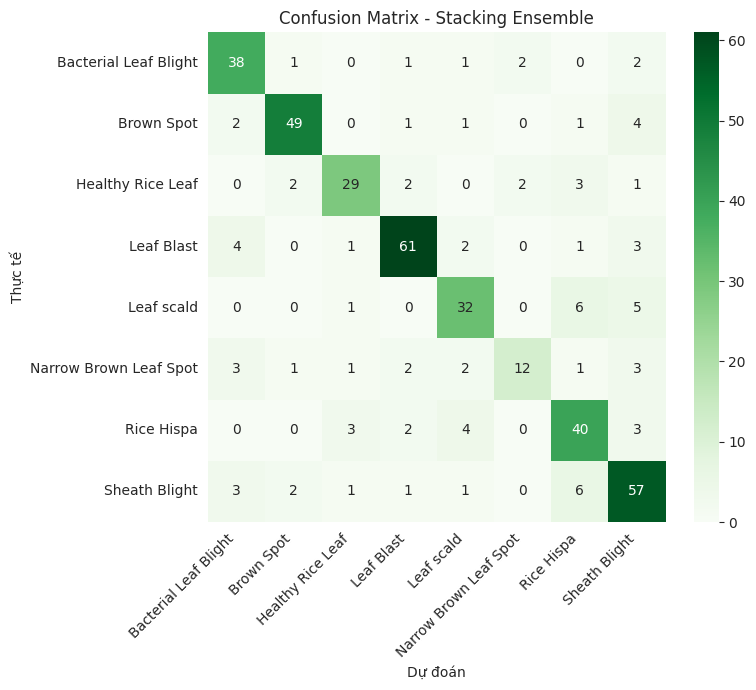


Bảng tổng hợp F1-macro tất cả phương án:
VotingEnsemble        0.770915
StackingEnsemble      0.764140
SVM                   0.756858
LogisticRegression    0.722932
DecisionTree          0.535812
KNN                   0.511613
dtype: float64

🏆 Mô hình tốt nhất: VotingEnsemble (F1-macro = 0.7709)


In [10]:
from sklearn.ensemble import StackingClassifier

stacking_clf = StackingClassifier(
    estimators=[
        ("svm", SVC(kernel="rbf", C=10, gamma="scale",
                     probability=True, random_state=CFG.RANDOM_STATE)),
        ("knn", KNeighborsClassifier(n_neighbors=5)),
        ("dt", DecisionTreeClassifier(max_depth=15, random_state=CFG.RANDOM_STATE)),
        ("lr", LogisticRegression(max_iter=2000, random_state=CFG.RANDOM_STATE)),
    ],
    final_estimator=LogisticRegression(max_iter=2000, random_state=CFG.RANDOM_STATE),
    stack_method="predict_proba",   # dùng xác suất làm input cho meta model
    cv=5,                            # cross-validation để tránh leakage khi tạo meta-features
    n_jobs=-1,
    passthrough=False,               # True nếu muốn meta model thấy cả X gốc + dự đoán base
)

stacking_clf.fit(X_train, y_train)
y_pred_stack = stacking_clf.predict(X_val)

acc_stack = accuracy_score(y_val, y_pred_stack)
f1_stack = f1_score(y_val, y_pred_stack, average="macro")
print(f"Stacking Ensemble - Accuracy: {acc_stack:.4f} | F1-macro: {f1_stack:.4f}")

print("\nClassification report (Stacking Ensemble):")
print(classification_report(
    y_val, y_pred_stack, target_names=list(label_mapping.keys())
))

cm_stack = confusion_matrix(y_val, y_pred_stack)
plt.figure(figsize=(8, 7))
sns.heatmap(
    cm_stack, annot=True, fmt="d", cmap="Greens",
    xticklabels=list(label_mapping.keys()),
    yticklabels=list(label_mapping.keys()),
)
plt.xlabel("Dự đoán")
plt.ylabel("Thực tế")
plt.title("Confusion Matrix - Stacking Ensemble")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# So sánh và chọn mô hình tốt nhất trong TẤT CẢ các lựa chọn
# (4 mô hình đơn + Voting + Stacking), dựa trên F1-macro trên tập validation
all_scores = {
    **{k: v["f1_macro"] for k, v in results.items()},
    "VotingEnsemble": f1_vote,
    "StackingEnsemble": f1_stack,
}
best_name = max(all_scores, key=all_scores.get)

if best_name == "VotingEnsemble":
    best_model = voting_clf
elif best_name == "StackingEnsemble":
    best_model = stacking_clf
else:
    best_model = trained_models[best_name]

print("\nBảng tổng hợp F1-macro tất cả phương án:")
print(pd.Series(all_scores).sort_values(ascending=False))
print(f"\n🏆 Mô hình tốt nhất: {best_name} (F1-macro = {all_scores[best_name]:.4f})")

# PHẦN 6: Dự đoán tập test và tạo submission.csv

In [11]:
def build_test_file_list(test_dir):
    """Thu thập danh sách file ảnh trong tập test (không có nhãn)."""
    records = []
    for fname in sorted(os.listdir(test_dir)):
        if fname.lower().endswith((".jpg", ".jpeg", ".png")):
            records.append({
                "filepath": os.path.join(test_dir, fname),
                "image_id": fname,
            })
    return pd.DataFrame(records)


test_df = build_test_file_list(CFG.TEST_DIR)
print("Tổng số ảnh test:", test_df.shape[0])


def build_test_feature_matrix(df):
    X_test = []
    for _, row in tqdm(df.iterrows(), total=len(df)):
        img = load_and_preprocess_image(row["filepath"])
        feat = extract_combined_features(img)
        X_test.append(feat)
    return np.array(X_test)


X_test_raw = build_test_feature_matrix(test_df)
X_test_scaled = scaler.transform(X_test_raw)  # dùng lại scaler đã fit trên train

test_pred = best_model.predict(X_test_scaled)

# ⚠️ Kiểm tra format của sample_submission.csv trước khi lưu file cuối cùng
if os.path.exists(CFG.SAMPLE_SUB_PATH):
    sample_sub = pd.read_csv(CFG.SAMPLE_SUB_PATH)
    print("Các cột trong sample_submission.csv:", sample_sub.columns.tolist())
    print(sample_sub.head())

submission = pd.DataFrame({
    "image_id": test_df["image_id"],
    "label": test_pred,        # nếu sample yêu cầu tên bệnh thay vì số, dùng dòng dưới
    # "label": [idx_to_class[p] for p in test_pred],
})

submission.to_csv("submission.csv", index=False)
print("✅ Đã lưu submission.csv")
submission.head()

Tổng số ảnh test: 300


100%|██████████| 300/300 [00:16<00:00, 18.44it/s]


✅ Đã lưu submission.csv


,image_id,label
0,public_0001.jpg,6
1,public_0002.jpg,6
2,public_0003.jpg,3
3,public_0004.jpg,6
4,public_0005.jpg,4


# PHẦN 7: Tối ưu tham số bằng GridSearchCV / RandomizedSearchCV

In [12]:
from scipy.stats import randint

# --- Tối ưu SVM bằng GridSearchCV (không gian tìm kiếm nhỏ, tìm chính xác) ---
param_grid_svm = {
    "C": [1, 5, 10, 20],
    "gamma": ["scale", 0.01, 0.001],
    "kernel": ["rbf"],
}
grid_svm = GridSearchCV(
    SVC(probability=True, random_state=CFG.RANDOM_STATE),
    param_grid_svm, cv=3, scoring="f1_macro", n_jobs=-1, verbose=1,
)
grid_svm.fit(X_train, y_train)
print("Best SVM params:", grid_svm.best_params_)
print("Best CV F1-macro:", grid_svm.best_score_)

best_svm = grid_svm.best_estimator_
y_pred_best_svm = best_svm.predict(X_val)
print("SVM sau tối ưu - Accuracy:", accuracy_score(y_val, y_pred_best_svm))
print("SVM sau tối ưu - F1-macro:", f1_score(y_val, y_pred_best_svm, average="macro"))

# --- Tối ưu KNN bằng RandomizedSearchCV (không gian tìm kiếm lớn, lấy mẫu ngẫu nhiên) ---
param_dist_knn = {
    "n_neighbors": randint(3, 15),
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}
random_knn = RandomizedSearchCV(
    KNeighborsClassifier(), param_dist_knn, n_iter=15, cv=3,
    scoring="f1_macro", random_state=CFG.RANDOM_STATE, n_jobs=-1, verbose=1,
)
random_knn.fit(X_train, y_train)
print("Best KNN params:", random_knn.best_params_)
print("Best CV F1-macro:", random_knn.best_score_)

# Nếu mô hình tối ưu tốt hơn best_model hiện tại, dùng nó để dự đoán lại tập test
if grid_svm.best_score_ > all_scores[best_name]:
    print("Dùng SVM đã tối ưu để dự đoán lại tập test...")
    test_pred_optimized = best_svm.predict(X_test_scaled)
    submission_optimized = pd.DataFrame({
        "image_id": test_df["image_id"],
        "label": test_pred_optimized,
    })
    submission_optimized.to_csv("submission.csv", index=False)
    print("✅ Đã cập nhật submission.csv với mô hình tối ưu")

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best SVM params: {'C': 5, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV F1-macro: 0.6741218169014115
SVM sau tối ưu - Accuracy: 0.7758620689655172
SVM sau tối ưu - F1-macro: 0.756857919050719
Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best KNN params: {'n_neighbors': 4, 'p': 2, 'weights': 'distance'}
Best CV F1-macro: 0.6513297746355258


# PHẦN 8: Giải thích chi tiết từng hàm và cách trình bày trong báo cáo
#
## 8.1. Giải thích các hàm tiền xử lý
- `load_and_preprocess_image(path, size)`: đọc ảnh bằng OpenCV (BGR mặc định),
  chuyển sang RGB để hiển thị/xử lý đúng màu, resize về kích thước cố định
  (128x128) để mọi ảnh có cùng số chiều đặc trưng khi trích xuất HOG/LBP.
#
## 8.2. Giải thích các hàm trích xuất đặc trưng
- `extract_hog_features`: chuyển ảnh sang grayscale, tính gradient theo
  từng ô (cell) 8x8 pixel, gộp thành block 2x2 cell để chuẩn hóa cục bộ.
  Kết quả là vector mô tả **hình dạng/đường viền** vết bệnh.
- `extract_lbp_features`: so sánh độ sáng mỗi pixel với 24 pixel lân cận
  (bán kính 3), mã hóa thành số nhị phân, rồi thống kê tần suất xuất hiện.
  Kết quả là vector mô tả **kết cấu bề mặt** lá (mượt, sần sùi, lốm đốm).
- `extract_color_histogram`: thống kê phân bố cường độ màu trên 3 kênh
  R, G, B (32 bin mỗi kênh). Kết quả mô tả **màu sắc đặc trưng** của
  từng loại bệnh (vàng, nâu, đỏ, xanh...).
- `extract_combined_features`: nối 3 vector trên thành 1 vector đặc trưng
  duy nhất — kết hợp cả hình dạng, kết cấu và màu sắc để mô hình học
  phân biệt tốt hơn so với chỉ dùng 1 loại đặc trưng.
#
## 8.3. Giải thích các hàm xây dựng dữ liệu
- `build_file_list`: duyệt cấu trúc thư mục train/<tên_lớp>/*.jpg, gán
  nhãn số theo label_mapping.json, trả về DataFrame (đường dẫn, nhãn).
- `build_feature_matrix`: áp dụng `extract_combined_features` cho toàn
  bộ ảnh trong DataFrame, trả về ma trận X (n_samples, n_features) và
  vector nhãn y.
- `build_test_file_list` / `build_test_feature_matrix`: tương tự nhưng
  cho tập test_images/ (không có nhãn).
#
## 8.4. Vì sao chuẩn hóa dữ liệu (StandardScaler)?
HOG/LBP/Color Histogram có thang giá trị khác nhau. SVM, KNN, Logistic
Regression đều nhạy cảm với thang đo (scale) của đặc trưng, nên cần
chuẩn hóa về trung bình 0, phương sai 1 trước khi huấn luyện.
#
## 8.5. Vì sao dùng Voting Ensemble?
Mỗi mô hình có điểm mạnh khác nhau: SVM tốt với biên phân tách phi tuyến,
KNN tốt khi dữ liệu có cụm rõ ràng, Decision Tree dễ diễn giải, Logistic
Regression ổn định với dữ liệu tuyến tính. Soft Voting lấy trung bình
xác suất dự đoán của các mô hình, giúp giảm phương sai và tăng độ ổn định
so với chỉ dùng 1 mô hình đơn lẻ.
#
## 8.5b. Vì sao dùng Stacking Ensemble?
Stacking khác Voting ở chỗ nó KHÔNG chỉ lấy trung bình/đa số phiếu, mà
huấn luyện thêm một "meta model" (ở đây là Logistic Regression) để HỌC
cách kết hợp tối ưu dự đoán của các mô hình gốc. Cụ thể:
1. Với `cv=5`, dữ liệu train được chia 5 phần; mỗi mô hình gốc lần lượt
   dự đoán xác suất trên phần dữ liệu nó *chưa* được huấn luyện —
   tránh rò rỉ thông tin (data leakage) khi tạo "meta-features".
2. Các xác suất dự đoán này (không phải dữ liệu gốc) trở thành input
   cho meta model, giúp meta model học được: "khi nào nên tin SVM hơn,
   khi nào nên tin Logistic Regression hơn..." tùy theo pattern dự đoán.
3. Vì có bước học tối ưu thay vì chỉ lấy trung bình cố định, Stacking
   thường cho kết quả tốt hơn Voting khi các mô hình gốc có độ mạnh/yếu
   khác biệt rõ rệt — đúng như trường hợp SVM/LogReg vượt trội hơn
   Decision Tree/KNN trong bài toán này.
#
## 8.6. Vì sao dùng GridSearchCV / RandomizedSearchCV?
- GridSearchCV: duyệt toàn bộ tổ hợp tham số trong một lưới nhỏ,
  đảm bảo tìm được tham số tối ưu nhưng chi phí tính toán cao khi
  không gian tham số lớn.
- RandomizedSearchCV: lấy mẫu ngẫu nhiên một số tổ hợp tham số,
  phù hợp khi không gian tham số lớn, tiết kiệm thời gian mà vẫn
  thường tìm được cấu hình tốt gần tối ưu.
#
## 8.7. Gợi ý trình bày báo cáo
1. **Giới thiệu bài toán**: mục tiêu, dataset, số lớp, số lượng ảnh.
2. **Tiền xử lý & EDA**: phân bố lớp, ảnh mẫu, nhận xét mất cân bằng
   dữ liệu (nếu có).
3. **Phương pháp trích xuất đặc trưng**: giải thích HOG/LBP/Color
   Histogram, minh họa trực quan (ví dụ ảnh HOG, ảnh LBP).
4. **Mô hình huấn luyện**: liệt kê 4 mô hình, tham số mặc định, kết quả
   accuracy/F1-macro trên tập validation (bảng so sánh).
5. **Voting Ensemble**: giải thích cách kết hợp, confusion matrix,
   nhận xét lớp nào mô hình hay nhầm lẫn nhất và lý do (hình dạng/màu
   sắc bệnh tương đồng).
6. **Tối ưu tham số**: trình bày kết quả GridSearchCV/RandomizedSearchCV,
   so sánh trước/sau tối ưu.
7. **Kết quả dự đoán tập test & submission.csv**.
8. **Kết luận & hướng cải thiện**: có thể đề xuất thêm đặc trưng
   (GLCM, SIFT/ORB, deep features từ CNN pretrained), xử lý mất cân
   bằng lớp (SMOTE, class_weight), hoặc thử thêm mô hình khác
   (Random Forest, XGBoost).
#
## 8.8. Điểm 0.58 chưa cao — vài hướng cải thiện thêm nếu còn thời gian
- **Đặc trưng thủ công (HOG/LBP/Color) có giới hạn** với bài toán bệnh lá
  phức tạp — nếu quy chế cho phép, dùng **deep features** (trích đặc trưng
  từ một CNN pretrained như ResNet18/MobileNet, KHÔNG fine-tune, chỉ lấy
  vector đặc trưng ở lớp áp chót) rồi đưa vào các mô hình ML này thường
  cải thiện đáng kể so với HOG/LBP/Color thuần túy.
- **Xử lý mất cân bằng lớp**: nếu EDA ở Phần 3 cho thấy lớp lệch nhau
  nhiều, thử `class_weight="balanced"` cho SVM/LogReg/DecisionTree, hoặc
  oversampling bằng SMOTE trên feature matrix (không phải trên ảnh gốc).
- **Tăng kích thước ảnh** (vd 128→224) để HOG/LBP nắm chi tiết hơn, đổi
  lại thời gian trích đặc trưng lâu hơn.
- **Thêm đặc trưng kết cấu khác**: GLCM (Gray-Level Co-occurrence Matrix)
  thường bổ sung tốt cho LBP trong bài toán phân biệt bệnh lá.
- **Passthrough=True trong StackingClassifier**: cho meta model thấy cả
  feature gốc lẫn dự đoán của base model, đôi khi tăng nhẹ độ chính xác
  — nên thử nghiệm so sánh có/không.
- Luôn kiểm tra lại **confusion matrix**: nếu 2-3 lớp bệnh bị nhầm lẫn
  nhiều nhất với nhau, thử huấn luyện thêm 1 mô hình phụ chỉ để phân
  biệt riêng các lớp đó (hierarchical classification).